In [16]:
# import statements

# import pyphenom
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from lmfit import Model, models
from scipy.optimize import minimize
import warnings


In [17]:
# helper functions

def auto_correlation(frame):
    """
    Returns the computed auto_correlation for a given frame.

    Parameter frame: an SEM image
    """

    ft = np.fft.fft2(frame)
    autocorr = np.fft.ifft2(ft * np.conjugate(ft))
    return np.fft.fftshift(autocorr).real


def gaussian2d_with_offset(x, y, amplitude, centerx, centery, sigmax, sigmay, correlation, offset):
    """
    Returns a bivariate normal distribution equation for a given set of parameters.

    Parameter x: a numpy meshgrid representing the x-axis
    Parameter y: a numpy meshgrid representing the y-axis
    Parameter amplitude: a number representing the amplitude of the distribution
    Parameter centerx: a number representing the mean value of the x-values
    Parameter centery: a number representing the mean value of the y-values
    Parameter sigmax: a number representing the standard deviation in the x-direction
    Parameter sigmay: a number representing the standard deviation in the y-direction
    Parameter correlation: a number representing the correlation between the two indepedent variables x and y
    Parameter offset: a number representing the offset between the distribution and the x = y = 0 plane
    """

    xterm = (x - centerx) / sigmax 
    yterm = (y - centery) / sigmay
    exponent = (-1 / (2 * (1 - correlation**2))) * (xterm**2 + yterm**2 - 2 * correlation * xterm * yterm)
    constant = amplitude / (2 * np.pi * sigmax * sigmay * np.sqrt(1 - correlation**2))
    return constant * np.exp(exponent) + offset


def covariance_matrix(ac): # if code too slow, consider fitting with scipy instead of lmfit
    """
    Returns the computed covariance matrix given the auto_correlation data.

    Parameter ac: a 2d array with values corresponding to the auto_correlation data at each position i,j
    """

    model = Model(gaussian2d_with_offset, independent_vars=['x', 'y']) # creates a model using lmfit that the data is going to be fitted to

    nrows = len(ac)
    ncols = len(ac[0])

    x_val, y_val = np.meshgrid(np.linspace(0, ncols, ncols), np.linspace(0, nrows, nrows)) # creates the x and y array values

    mod = models.Gaussian2dModel() 
    pars = mod.guess(ac.flatten(), x_val.flatten(), y_val.flatten()) # uses lmfit Gaussian2dModel to get initial parameter guesses
    pars.add("offset", value = np.min(ac)) # uses the minimum value of the autocorrelation data as a offset value guess
    pars.add("correlation", value = 0, min = -1, max = 1) # uses 0 as a correlation value guess

    result = model.fit(ac, x = x_val, y = y_val, params = pars) # uses the above parameters and  model to fit the data
    #print(result.fit_report())

    # shows the contour plot of the fit plotted on top of the contour plot of the data
    #fig, ax = plt.subplots()
    #ax.contour(np.linspace(0, ncols, ncols), np.linspace(0, nrows, nrows), ac)
    #ax.contour(np.linspace(0, ncols, ncols), np.linspace(0, nrows, nrows), result.best_fit)
    #plt.show()

    covarxx = result.best_values["sigmax"]**2
    covarxy = result.best_values["correlation"] * result.best_values["sigmax"] * result.best_values["sigmay"]
    covaryy = result.best_values["sigmay"]**2
    #covar_matrix = [[covarxx, covarxy], [covarxy, covaryy]] # Calculates covariance matrix
    covar_matrix = {"covarxx": covarxx, "covaryy": covaryy, "covarxy": covarxy}
    
    return covar_matrix


def minimum(x, y, degree):
    """
    Calculates the minimum value and the position of its occurence given a data set x and y 
    and the degree of the polynomial to be fitted.

    Parameter x: a 1D list of x-coordinates
    Parameter y: a 1D list of corresponding y-coordinates
    Parameter degree: an int representing the maximum degree of the polynomial to be fitted
    """

    warnings.filterwarnings("error", category=np.RankWarning)

    eqn = None

    while eqn is None:
        try:
            coeff = np.polyfit(x, y, degree) # fits the data to a polynomial equation that is a good fit (doesn't give a RankWarning)
            eqn = np.poly1d(coeff)  

        except:                                                 
            degree = degree - 1

    x0 = 0 # initial guess for minimum
    result = minimize(eqn, x0)

    return {"min_val": result.fun, "min_x": result.x[0], "fitted_eqn": eqn}


def focus(type, num_pic, val_min, val_max):
    """
    Returns the working distance, x-direction stigmate, or y-direction stigmate corresponding to the best image.
    The value returned depends on the parameters type, num_pic, val_min, and val_max.

    Parameter type: the string "wd", "xst", or "yst", corresponding to working distance, x-direction stigmate, and y-direction stigmate
    Parameter num_pic: the number of pictures taken
    Parameter val_min: the minimum value of wd, xst, or yst that a picture is taken at
    Parameter val_max: the maximum value of wd, xst, or yst that a picture is taken at
    """
    
    val_range = np.linspace(val_min, val_max, num_pic) # creates equally spaced values that pictures are taken at
    covarxx_data = []
    covaryy_data = []
    covarxy_data = []

    for i in range(len(val_range)):
        # set wd to number in wd_range 
        # img = # take and access image and  convert to np array -> works rn, might need to test other options if doesn't work
        image_path = "semtest.jpg" # this and next line will get replaced later
        img = Image.open(image_path).convert('L') # in test had to grayscale but probably dont need to cuz sem is automatically grayscale
        img_array = np.array(img) # converts image into an array
        acdata = auto_correlation(img_array) # calculates the auto_correlation data
        covar_data = covariance_matrix(acdata) # calculates the covariance matrix

        if type == "wd":
            covarxx_data.append(covar_data["covarxx"]) # finds the covarxx and covaryy data for working distance calibration
            covaryy_data.append(covar_data["covaryy"])

        elif type == "xst" or type == "yst":
            covarxy_data.append(covar_data["covarxy"]) # finds the covarxy data for stigmate calibration

    if type == "wd": # calculates the minimum and the new range for working distance calibration
        x_data = minimum(val_range, covarxx_data, num_pic) 
        y_data = minimum(val_range, covaryy_data, num_pic)
        range_bottom = max((min(x_data["min_x"], y_data["min_x"]) - ((val_max - val_min) / 2)), val_min) # can change 2 depending on testing ig
        range_top = min((max(x_data["min_x"], y_data["min_x"]) + ((val_max - val_min) / 2)), val_max) # ^
        return {"range_bottom": range_bottom, "range_top": range_top, "x_data": x_data, "y_data": y_data}

    elif type == "xst" or type == "yst": # calculates the minimum and the new range for stigmate calibration
        data = minimum(val_range, covarxy_data, num_pic) 
        range_bottom = max(data["min_x"] - ((val_max - val_min) / 2), val_min) # can change 2 depending on testing ig
        range_top = min(data["min_x"] + ((val_max - val_min) / 2), val_max) # ^
        return {"range_bottom": range_bottom, "range_top": range_top, "data": data}


def auto_focus(num_pic, wd_val_min, wd_val_max, st_val_min, st_val_max):
    """
    Sets the working distance, x-direction stigmate, and y-direction stigmate to the values needed for a focused image.

    Parameter num_pic: the number of pictures taken
    Parameter val_min: the minimum value of wd, xst, or yst that a picture is taken at
    Parameter val_max: the maximum value of wd, xst, or yst that a picture is taken at
    """

    xwd_prev_val = None
    xwd_cur_val = None
    xwd_sig = None
    xwd_eqn = None
    ywd_prev_val = None
    ywd_cur_val = None
    ywd_sig = None
    ywd_eqn = None
    wd_small = 0.001 # change later depending on smallest sig fig

    xst_prev_val = None
    xst_cur_val = None
    yst_prev_val = None
    yst_cur_val = None
    st_small = 0.001 # change later depending on smallest sig fig   

    while True:
        new_vals = focus("wd", num_pic, wd_val_min, wd_val_max) # call with wd data
        xwd_cur_val = new_vals["x_data"]["min_x"]
        ywd_cur_val = new_vals["y_data"]["min_x"]
        xwd_sig = new_vals["x_data"]["min_val"]
        xwd_eqn = new_vals["x_data"]["fitted_eqn"]
        ywd_sig = new_vals["y_data"]["min_val"]
        ywd_eqn = new_vals["y_data"]["fitted_eqn"]

        if (xwd_prev_val is not None and ywd_prev_val is not None and (np.absolute(xwd_cur_val - xwd_prev_val) < wd_small) and 
            (np.absolute(ywd_cur_val - ywd_prev_val) < wd_small)): # repeat until the change in values is small
            break 

        xwd_prev_val = xwd_cur_val 
        ywd_prev_val = ywd_cur_val

    if round(xwd_cur_val, 3) == round(ywd_cur_val, 3): # change the 3 to whatever number of decimal places i need from st_small
        # wd = round(xwd_cur_val, 3)
        pass

    else: # if the wd for x and y aren't the same, then compare the sigy value at xwd with the sigy value at ywd and 
        ysig_xwd = xwd_eqn(xwd_cur_val)                 # the sigx value at ywd with the sigx value at xwd and calculate the difference
        xsig_ywd = ywd_eqn(ywd_cur_val)                 # and choose the wd with the smallest difference
        y_diff = np.absolute(ysig_xwd - ywd_sig)
        x_diff = np.absolute(xsig_ywd - xwd_sig)

        if min(x_diff, y_diff) == x_diff:
            #wd = round(xwd_cur_val, 3)
            pass
    
        else:
            #wd = round(ywd_cur_val, 3)
            pass

    while True:
        new_vals = focus("xst", num_pic, st_val_min, st_val_max) # call with xst data
        xst_cur_val = new_vals["data"]["min_x"]

        if xst_prev_val is not None and (np.absolute(xst_cur_val - xst_prev_val) < st_small): # repeat until the change in values is small
            break 

        xst_prev_val = xst_cur_val 

    #then set xst equal to xst_current_val

    while True:
        new_vals = focus("yst", num_pic, st_val_min, st_val_max) # call with yst data
        yst_cur_val = new_vals["data"]["min_x"]

        if yst_prev_val is not None and (np.absolute(yst_cur_val - yst_prev_val) < st_small): # repeat until the change in values is small
            break 

        yst_prev_val = yst_cur_val 

    #then set yst equal to yst_current_val

In [ ]:
# main thing 

# connect to SEM 
# can look at the example file or manual for SEM number thing, username, password
# example file is under ThermoFisher/Andreas/ something...ipynb

num_pic = 10 # change later depending on testing
wd_val_min = 5 # need to set min wd in sweep region
wd_val_max = 10 # need to set max wd in sweep region, figure out decent numbers later
st_val_min = 5 # need to set min wd in sweep region
st_val_max = 10 # need to set max wd in sweep region, figure out decent numbers later

auto_focus(num_pic, wd_val_min, wd_val_max, st_val_min, st_val_min)


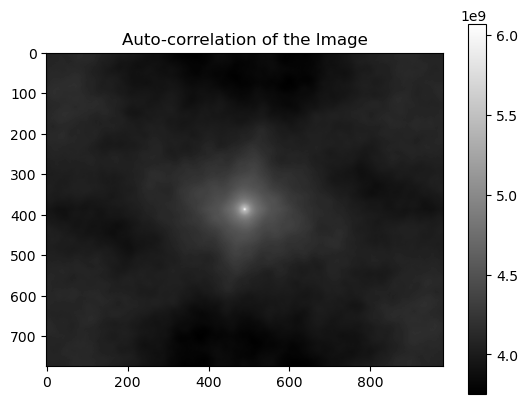

C:\Users\rzhou\AppData\Roaming\Python\Python311\site-packages\uncertainties\core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")


{'covarxx': 10014.909122705523, 'covaryy': 6057.728992183825, 'covarxy': 866.5167430988029}


In [18]:
# TEST IMAGE TO SEE IF CODE RUNS WITH AN IMAGE

# take picture, save picture and then access image
# load and convert image to grayscale (for testing with downloaded pics)
# might need to change with actual SEM live pics
image_path = "semtest.jpg"
img = Image.open(image_path).convert('L')
img_array = np.array(img)
# Image.fromarray() function is used to convert back, which takes a NumPy array as input and creates a PIL Image object

# compute auto_correlation and generate the auto_correlation plot
acdata = auto_correlation(img_array)

plt.imshow(acdata, cmap='gray')
plt.title('Auto-correlation of the Image')
plt.colorbar()
plt.show()

result = covariance_matrix(acdata)
print(result)

In [15]:
# compute covariance marix from autocorrelation (NO CORRELATION VALUE IN FIT EQN)

def gaussian2d_with_offset(x, y, amplitude, centerx, centery, sigmax, sigmay, offset):
    exponent = -(((x - centerx) / sigmax)**2 + ((y - centery) / sigmay)**2) / 2.0
    return amplitude * np.exp(exponent) + offset

def gaussian2d_model_with_offset(x, y, amplitude, centerx, centery, sigmax, sigmay, offset):
    return gaussian2d_with_offset(x, y, amplitude, centerx, centery, sigmax, sigmay, offset)

model = Model(gaussian2d_model_with_offset, independent_vars=['x', 'y'])

nrows = len(acdata)
ncols = len(acdata[0])

x_val, y_val = np.meshgrid(np.linspace(0, ncols, ncols), np.linspace(0, nrows, nrows))

mod = models.Gaussian2dModel()
pars = mod.guess(acdata.flatten(), x_val.flatten(), y_val.flatten())
pars.add("offset",value=np.min(acdata))

out = model.fit(acdata, x = x_val, y = y_val, params = pars)
print(out.fit_report())
print(out.best_values)
print(out.var_names)
print(out.covar)

[[Model]]
    Model(gaussian2d_model_with_offset)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 64
    # data points      = 758520
    # variables        = 6
    chi-square         = 5.9039e+21
    reduced chi-square = 7.7835e+15
    Akaike info crit   = 27754847.3
    Bayesian info crit = 27754916.6
    R-squared          = 0.64267825
[[Variables]]
    amplitude:  7.1338e+08 +/- 807577.822 (0.11%) (init = 4.874203e+13)
    centerx:    490.500510 +/- 0.11086779 (0.02%) (init = 490.5005)
    centery:    387.500655 +/- 0.08802192 (0.02%) (init = 387.5006)
    sigmax:     97.9417498 +/- 0.11543595 (0.12%) (init = 163.3333)
    sigmay:     77.7572169 +/- 0.09164873 (0.12%) (init = 129)
    fwhmx:      230.635191 +/- 0.27183089 (0.12%) == '2.3548200*sigmax'
    fwhmy:      183.104250 +/- 0.21581625 (0.12%) == '2.3548200*sigmay'
    height:     14908.5340 +/- 38.9860663 (0.26%) == '0.1591549*amplitude/(max(1e-15, sigmax)*max(1e-15, sigmay))'
    offset:     3.9

C:\Users\rzhou\AppData\Roaming\Python\Python311\site-packages\uncertainties\core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")


In [ ]:
# new idea: take a bunch of pictures while modifying the focus and obtain the covar matrices for all of them
# find a way to measure the smallest covar matrix (sum of all the terms?) and plot the size vs wd (quadratic ish)
# find the wd at the minimum
# repeat for stigmate x and stigmate y and then theoretically should be focused

# take like ten images through a wide sweep range? idk maybe like 10 mm ? gotta rework this number while testing tho
# calculate covar matrix for all of them and create a graph and find the min
# maybe should repeat again through a smaller range while focused more closely at the calculated min to fine tune

def focus_stigmate():
    st_max = 10 # need to set max wd in sweep region, figure out decent numbers later
    st_min = 5 # need to set min wd in sweep region
    num_pic = 10
    st_range = np.linspace(st_min, st_max, num_pic)

    covarxy_data = []
    st_data = []

    for w in range(len(st_range)):
        # set wd to number in wd_range 
        # img = # take and access image and  convert to np array -> works rn, might need to test other options if doesn't work
        img_array = np.array(img) # in test had to grayscale but probably dont need to cuz sem is automatically grayscale
        acdata = auto_correlation(img_array)

        covar_data = covariance_matrix(acdata)
        covarxx_data.append(covar_data["covarxx"])
        covaryy_data.append(covar_data["covaryy"])

        wd_data.append(w)

    #for i in range(len(covar_data)):
     #   covarxx_data.append(covar_data[i]["covarxx"])
     #   covaryy_data.append(covar_data[i]["covaryy"])

    min_x = minimum(wd_data, covarxx_data)["min_x"]
    min_y = minimum(wd_data, covaryy_data)["min_x"]

    new_wd_range = np.linspace(min(min_x, min_y) - np.absolute(min_x - min_y), max(min_x, min_y) + np.absolute(min_x - min_y), num_pic)

    # Should i double check that the new wd versus covar has a min ? 
    # Should i recursively call until the difference in range is less than a certain number?


    